# 01 · Exploratory data analysis (M1)

Synthetic training data from `txncat data build` (seed 42), read from PostgreSQL (`txncat data load`), falling back to `data/generated/synthetic.csv` if the database is down.

Questions: how imbalanced are the classes, what do descriptions look like, how do amounts and dates differ by category, and is the merchant-grouped split leak-free?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

from txncat.config import REPO_ROOT
from txncat.db import make_engine

try:
    with make_engine().connect() as conn:
        df = pd.read_sql(text("SELECT * FROM transactions WHERE source = 'synthetic'"), conn)
    origin = "PostgreSQL"
except Exception as exc:  # database not running
    df = pd.read_csv(REPO_ROOT / "data/generated/synthetic.csv", parse_dates=["posted_at"])
    origin = f"CSV ({type(exc).__name__})"
df["amount"] = df["amount"].astype(float)
print(f"{len(df):,} rows from {origin}")
df.head(8)

20,000 rows from PostgreSQL


,id,posted_at,description,amount,category,split,source
0,21304,2024-01-01,ACH DEBIT CAMDEN WATER DISTR,-46.21,Utilities,test,synthetic
1,21305,2024-01-01,ACH DEBIT CITY OF HOUSTON UTILIT,-50.71,Utilities,train,synthetic
2,21306,2024-01-01,ACH DEBIT RED PRAIRIE C,-2551.54,Rent & Lease,train,synthetic
3,21307,2024-01-01,ACH DEBIT TULSA PROPERTY MGMT 28,-2391.59,Rent & Lease,val,synthetic
4,21308,2024-01-01,ACH DEBIT WESTSIDE PLAZA,-1245.28,Rent & Lease,train,synthetic
5,21309,2024-01-01,ANDERSON OFFICE OUTFITTERS DETRO,-3.29,Office Supplies,train,synthetic
6,21310,2024-01-01,ATLANTA FUEL STOP SAN DIEGO C,-70.44,Fuel & Auto,train,synthetic
7,21311,2024-01-01,BEAR DIGITAL ADS SALT LAK,-106.42,Advertising & Marketing,train,synthetic


## Class balance
Imbalanced on purpose (SPEC §3b). Macro-F1 will matter more than accuracy.

In [2]:
counts = df["category"].value_counts()
print(f"largest/smallest class ratio: {counts.max() / counts.min():.1f}x")
pd.crosstab(df["category"], df["split"], margins=True)[["train", "val", "test", "All"]]

largest/smallest class ratio: 4.6x


split,train,val,test,All
category,,,,
Advertising & Marketing,785,136,181,1102
Bank Fees & Charges,715,195,147,1057
Fuel & Auto,1434,296,344,2074
Income / Deposits,1424,361,541,2326
Meals & Entertainment,1928,481,433,2842
Office Supplies,1217,322,299,1838
Other,722,175,153,1050
Professional Services,848,142,162,1152
Rent & Lease,449,89,75,613


## Description strings
Bank-style: ALL CAPS, truncated to 22–32 characters, processor prefixes.

In [3]:
df["desc_len"] = df["description"].str.len()
prefix_pattern = (
    r"^(SQ \*|TST\* |CLV\*|PAYPAL \*|SP |POS DEBIT|CHECKCARD|PURCHASE \d|DEBIT PURCHASE|"
    r"ACH DEBIT|ACH CREDIT|PADDLE\.NET\*|FS \*|2CO\.COM\*)"
)
df["prefix"] = df["description"].str.extract(prefix_pattern)[0]
print(df["desc_len"].describe()[["min", "50%", "max"]])
df["prefix"].fillna("(none)").value_counts().head(12)

min     3.0
50%    25.0
max    32.0
Name: desc_len, dtype: float64


prefix
(none)            10609
PAYPAL *           1171
DEBIT PURCHASE     1081
CHECKCARD          1069
POS DEBIT          1061
SQ *                990
PURCHASE 0          904
CLV*                639
ACH DEBIT           397
ACH CREDIT          371
TST*                325
2CO.COM*            310
Name: count, dtype: int64

## How easy is the synthetic data? (leakage / shortcut check)
If many descriptions literally contain a category word, models (and especially the LLM) get a shortcut. This is measured here and must be reported next to results (CLAUDE.md rule).

In [4]:
cues = {
    "Bank Fees & Charges": "FEE",
    "Shipping & Postage": r"SHIP|POST|MAIL|COURIER|FREIGHT",
    "Utilities": r"UTIL|WATER|POWER|ELECTRIC|FIBER|TELEPHONE",
    "Rent & Lease": r"LEASE|PROPERT|STORAGE|REALTY|COWORK",
    "Travel": r"HOTEL|INN|AIR|SUITES|LODGE|TRAVEL|LIMO",
    "Fuel & Auto": r"AUTO|GAS|FUEL|TIRE|LUBE|CAR WASH",
    "Professional Services": r"CPA|LAW|LLP|CONSULT|BOOKKEEP|TAX|STAFFING",
}
rows = []
for cat, pat in cues.items():
    sub = df[df["category"] == cat]
    rows.append((cat, pat, round(sub["description"].str.contains(pat).mean(), 2)))
pd.DataFrame(rows, columns=["category", "keyword pattern", "share of rows containing it"])

,category,keyword pattern,share of rows containing it
0,Bank Fees & Charges,FEE,0.64
1,Shipping & Postage,SHIP|POST|MAIL|COURIER|FREIGHT,0.61
2,Utilities,UTIL|WATER|POWER|ELECTRIC|FIBER|TELEPHONE,0.52
3,Rent & Lease,LEASE|PROPERT|STORAGE|REALTY|COWORK,0.57
4,Travel,HOTEL|INN|AIR|SUITES|LODGE|TRAVEL|LIMO,0.63
5,Fuel & Auto,AUTO|GAS|FUEL|TIRE|LUBE|CAR WASH,0.60
6,Professional Services,CPA|LAW|LLP|CONSULT|BOOKKEEP|TAX|STAFFING,0.66


## Amounts and dates

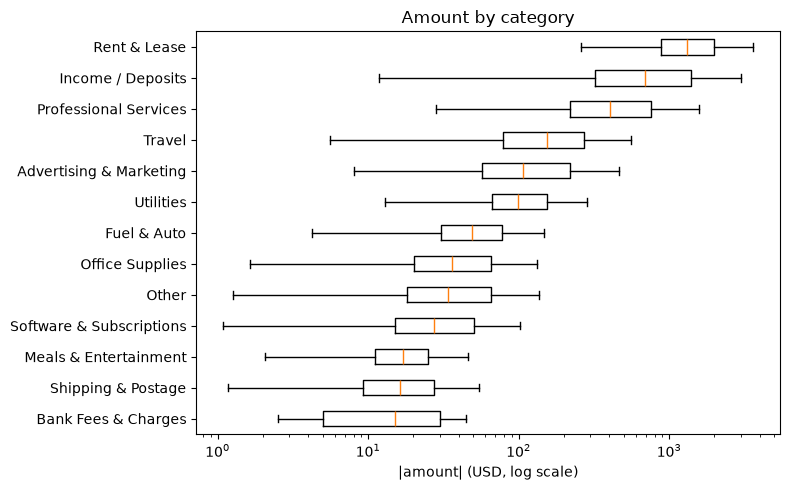

posted_at,Monday,Wednesday,Friday,Saturday,Sunday
category,,,,,
Advertising & Marketing,194,153,156,147,131
Bank Fees & Charges,137,164,147,142,152
Fuel & Auto,282,300,313,295,277
Income / Deposits,339,332,345,339,310
Meals & Entertainment,356,346,468,479,459
Office Supplies,270,281,273,248,235
Other,151,137,152,162,134
Professional Services,143,168,176,179,164
Rent & Lease,110,99,83,69,83


In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
order = df.groupby("category")["amount"].apply(lambda s: s.abs().median()).sort_values().index
ax.boxplot([df.loc[df["category"] == c, "amount"].abs() for c in order], orientation="horizontal", showfliers=False)
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_xscale("log")
ax.set_xlabel("|amount| (USD, log scale)")
ax.set_title("Amount by category")
plt.tight_layout()
plt.show()
df["posted_at"] = pd.to_datetime(df["posted_at"])
dow = pd.crosstab(df["category"], df["posted_at"].dt.day_name())
dow[["Monday", "Wednesday", "Friday", "Saturday", "Sunday"]]

## Split integrity
The database has no merchant column (by design: models must infer it), so this checks the generator output, which records each row's merchant.

In [6]:
gen = pd.read_csv(REPO_ROOT / "data/generated/synthetic.csv")
per_merchant = gen.groupby("merchant")["split"].nunique()
print("merchants in more than one split:", int((per_merchant > 1).sum()))
print("distinct merchants per split:", gen.groupby("split")["merchant"].nunique().to_dict())

merchants in more than one split: 0
distinct merchants per split: {'test': 584, 'train': 2734, 'val': 598}


## Takeaways
- 13 classes, imbalanced (largest/smallest ratio printed above); macro-F1 is the headline metric.
- Descriptions are short, truncated and prefix-heavy, like real statements.
- Some categories carry keyword cues (e.g. most bank fees say FEE). Real transactions often do too, but the synthetic set may be easier than reality: the hand-labeled `real_test` set is the honest check.
- No merchant crosses splits (count printed above), so test scores measure generalization to unseen merchants.
- Some calendar patterns are built in (rent on the 1st-3rd, subscriptions on a fixed day, fees late in the month, a mild weekend lean for meals); timing features should help, but not dominate.